In [1]:
from pycaret.classification import *
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score

In [2]:
# 1. Load the dataset
data = pd.read_csv('/Users/pjk/Wunderkammer/Machinelearning/Data/GlaucomaM.csv')

# Preview the data
print(data.sample(5))

        ag     at     as     an     ai    eag    eat    eas    ean    eai  \
190  3.904  0.743  0.885  1.317  0.960  3.687  0.713  0.845  1.205  0.924   
170  2.447  0.454  0.578  0.801  0.614  2.233  0.430  0.520  0.705  0.578   
141  2.847  0.515  0.690  0.926  0.717  2.385  0.497  0.580  0.699  0.608   
16   1.686  0.243  0.463  0.488  0.492  0.420  0.150  0.043  0.026  0.200   
137  2.401  0.402  0.616  0.751  0.632  1.969  0.376  0.575  0.478  0.539   

     ...    tmt    tms    tmn    tmi     mr    rnf   mdic    emd     mv  \
190  ...  0.152  0.162  0.084  0.146  1.117  0.165  0.322  0.341  0.027   
170  ...  0.281  0.184 -0.050  0.186  0.884  0.075  0.587  0.643  0.029   
141  ...  0.121 -0.007 -0.119  0.047  0.953  0.186  0.389  0.465  0.029   
16   ... -0.050 -0.159 -0.375 -0.114  0.735  0.184  0.012  0.047  0.018   
137  ...  0.031  0.029 -0.064  0.006  0.876  0.236  0.309  0.377  0.030   

        Class  
190  glaucoma  
170  glaucoma  
141  glaucoma  
16     normal  
137  g

In [3]:
# 2. Initialize the PyCaret Environment
# 'Class' is the target column based on the GlaucomaM dataset structure
s = setup(
    data=data, 
    target='Class', 
    session_id=42, 
    normalize=True,           # Normalize features
    transformation=True,      # Apply power transformations for skewness
    feature_selection=True,   # Automatically select important features
    fold=5                    # 5-fold cross-validation
)

[LightGBM] [Info] Number of positive: 69, number of negative: 68
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000246 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2649
[LightGBM] [Info] Number of data points in the train set: 137, number of used features: 62
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.503650 -> initscore=0.014599
[LightGBM] [Info] Start training from score 0.014599
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

,Description,Value
0,Session id,42
1,Target,Class
2,Target type,Binary
3,Target mapping,"glaucoma: 0, normal: 1"
4,Original data shape,"(196, 63)"
5,Transformed data shape,"(196, 13)"
6,Transformed train set shape,"(137, 13)"
7,Transformed test set shape,"(59, 13)"
8,Numeric features,62
9,Preprocess,True


In [4]:
# 3. Compare all available models to find the best performer
best_model = compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8683,0.9068,0.8683,0.8774,0.8670,0.7349,0.7447,0.2180
rf,Random Forest Classifier,0.8611,0.9113,0.8611,0.8714,0.8597,0.7207,0.7315,0.0880
et,Extra Trees Classifier,0.8534,0.9146,0.8534,0.8592,0.8526,0.7058,0.7119,0.0880
lightgbm,Light Gradient Boosting Machine,0.8466,0.9149,0.8466,0.8572,0.8449,0.6913,0.7026,0.1300
lr,Logistic Regression,0.8394,0.8986,0.8394,0.8492,0.8380,0.6773,0.6875,0.3560
nb,Naive Bayes,0.8394,0.8984,0.8394,0.8421,0.8390,0.6780,0.6810,0.2120
ada,Ada Boost Classifier,0.8312,0.8957,0.8312,0.8423,0.8282,0.6598,0.6718,0.0760
knn,K Neighbors Classifier,0.8243,0.8967,0.8243,0.8363,0.8223,0.6467,0.6593,0.2340
ridge,Ridge Classifier,0.8101,0.8835,0.8101,0.8207,0.8083,0.6185,0.6294,0.0700
svm,SVM - Linear Kernel,0.8026,0.8852,0.8026,0.8072,0.8013,0.6036,0.6088,0.0720


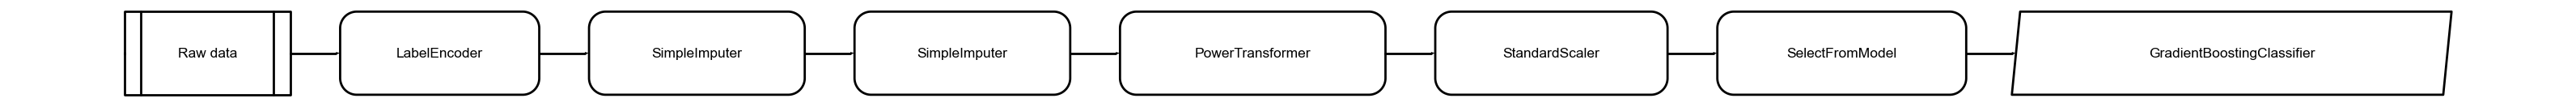

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

In [5]:
# 4. Analyze the best model (e.g., Confusion Matrix, AUC, Feature Importance)
evaluate_model(best_model)

In [6]:
# 5. Tune the best model hyperparameters
tuned_best_model = tune_model(best_model)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9286,0.9898,0.9286,0.9375,0.9282,0.8571,0.8660
1,0.8214,0.8571,0.8214,0.8231,0.8212,0.6429,0.6445
2,0.8889,0.9066,0.8889,0.9085,0.8870,0.7756,0.7959
3,0.8148,0.8791,0.8148,0.8298,0.8117,0.6260,0.6424
4,0.8889,0.9341,0.8889,0.8907,0.8886,0.7769,0.7790
Mean,0.8685,0.9133,0.8685,0.8779,0.8673,0.7357,0.7456
Std,0.0437,0.0462,0.0437,0.0446,0.0442,0.0880,0.0883


Fitting 5 folds for each of 10 candidates, totalling 50 fits


In [7]:
# 6. Finalize the model for deployment
final_model = finalize_model(tuned_best_model)

In [8]:
# 7. Save the model pipeline for future predictions
save_model(final_model, 'glaucoma_classification_model')
print("Model built, optimized, and saved successfully!")

Transformation Pipeline and Model Successfully Saved
Model built, optimized, and saved successfully!


In [10]:
print(tuned_best_model)

GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                           learning_rate=0.05, loss='log_loss', max_depth=6,
                           max_features='sqrt', max_leaf_nodes=None,
                           min_impurity_decrease=0.3, min_samples_leaf=4,
                           min_samples_split=10, min_weight_fraction_leaf=0.0,
                           n_estimators=270, n_iter_no_change=None,
                           random_state=42, subsample=0.7, tol=0.0001,
                           validation_fraction=0.1, verbose=0,
                           warm_start=False)


In [11]:
# Assuming 'best_model' was returned by compare_models()
holdout_predictions = predict_model(tuned_best_model)

# View the predictions (includes 'prediction_label' and 'prediction_score')
print(holdout_predictions.sample(10))

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.8475,0.8931,0.8475,0.8478,0.8474,0.6947,0.6951


        ag     at     as     an     ai    eag    eat    eas    ean    eai  \
7    1.835  0.312  0.463  0.578  0.483  0.687  0.226  0.247  0.023  0.192   
71   5.444  0.967  1.340  1.765  1.373  4.125  0.595  1.225  1.568  0.736   
118  2.833  0.528  0.676  0.935  0.693  2.123  0.480  0.525  0.588  0.529   
182  2.931  0.521  0.733  0.937  0.740  2.384  0.498  0.646  0.701  0.539   
169  3.328  0.594  0.812  1.076  0.846  2.939  0.554  0.695  0.966  0.724   
93   2.604  0.502  0.620  0.867  0.616  2.123  0.479  0.550  0.638  0.455   
14   2.620  0.450  0.658  0.836  0.676  1.718  0.434  0.426  0.304  0.554   
185  2.524  0.474  0.596  0.843  0.611  2.285  0.453  0.545  0.737  0.550   
184  1.727  0.384  0.352  0.610  0.381  1.226  0.278  0.291  0.438  0.220   
95   2.103  0.376  0.520  0.681  0.526  1.597  0.285  0.469  0.431  0.412   

     ...    tmn    tmi     mr    rnf   mdic    emd     mv     Class  \
7    ... -0.457 -0.250  0.764  0.263  0.058  0.155  0.023    normal   
71   ... -

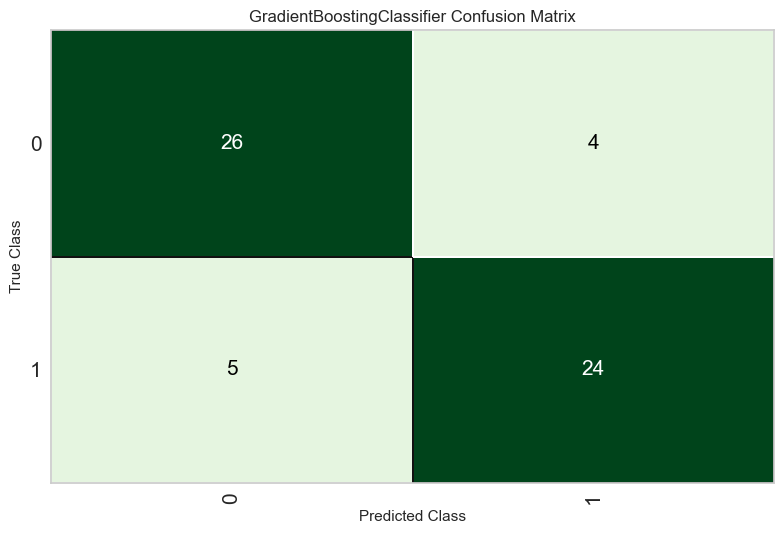

In [12]:
plot_model(tuned_best_model, plot='confusion_matrix')

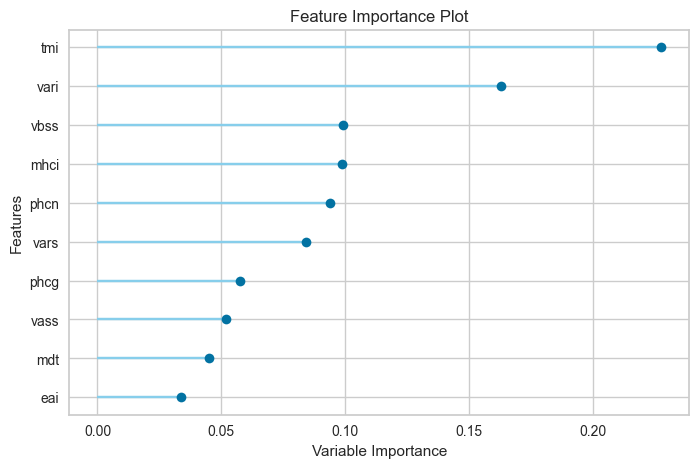

In [13]:
plot_model(tuned_best_model, plot='feature')

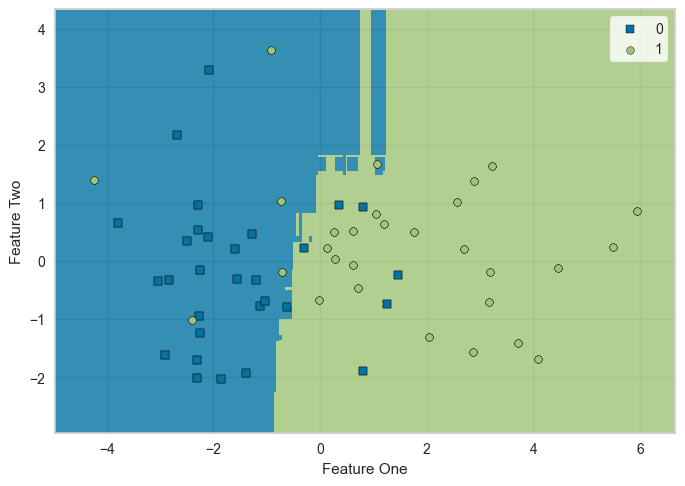

In [14]:
plot_model(tuned_best_model, plot='boundary')

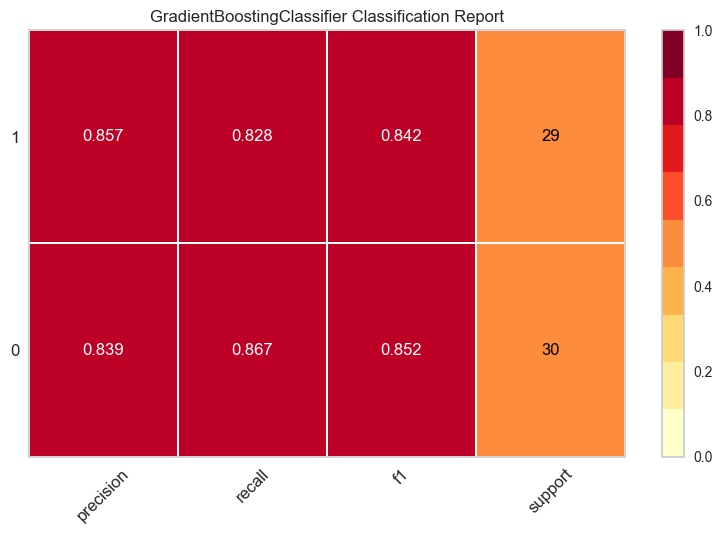

In [15]:
plot_model(tuned_best_model, plot='class_report')

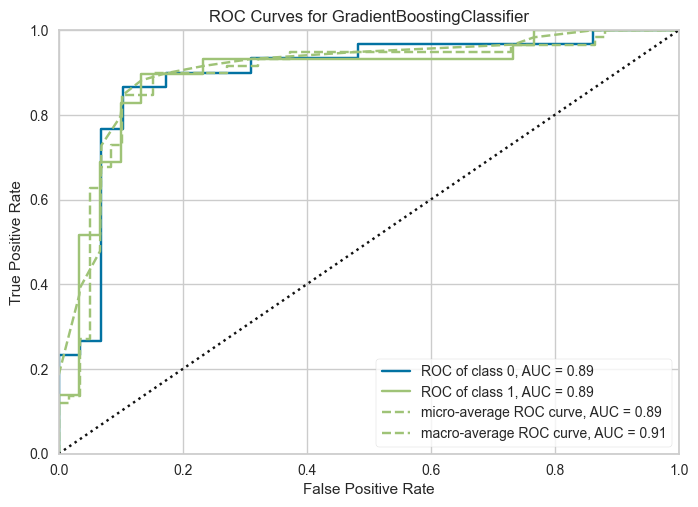

In [16]:
plot_model(tuned_best_model, plot='auc')

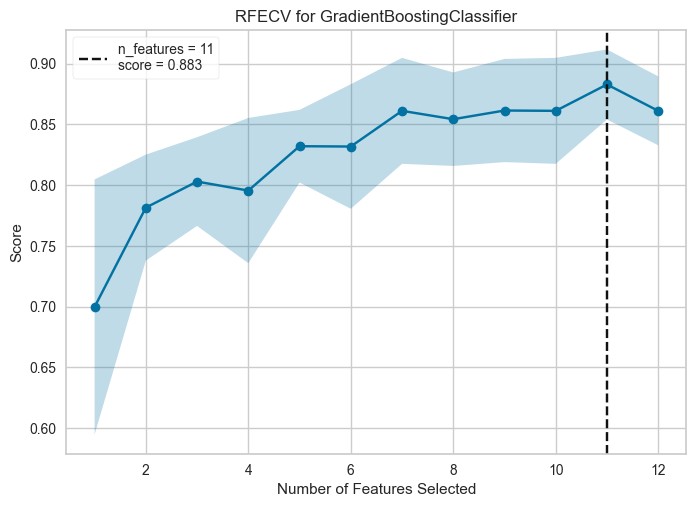

In [17]:
plot_model(tuned_best_model, plot='rfe')

**Classification Plots**
- 'auc': Area Under the ROC Curve   
- 'confusion_matrix': Confusion Matrix   
- 'pr': Precision-Recall Curve   
- 'threshold': Discrimination Threshold   
- 'class_report': Classification Report   
- 'error': Class Prediction Error   
- 'boundary': Decision Boundary   
- 'rfe': Recursive Feature Selection   
- 'learning': Learning Curve   
- 'manifold': Manifold Learning   
- 'calibration': Calibration Curve   
- 'feature': Feature Importance (Top 10)   
- 'feature_all': Feature Importance (All)   
- 'parameter': Model Hyperparameter   
- 'lift': Lift Curve   
- 'gain': Gain Curve   
- 'ks': Kolmogorov-Smirnov Statistic Plot   

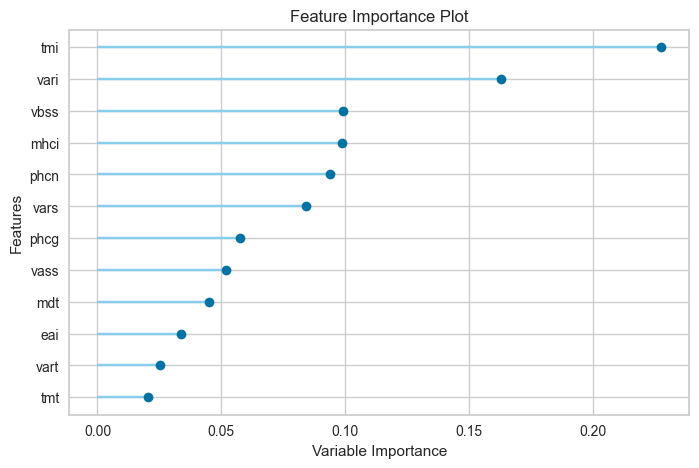

In [18]:
plot_model(tuned_best_model, plot='feature_all')

In [19]:
data.columns

Index(['ag', 'at', 'as', 'an', 'ai', 'eag', 'eat', 'eas', 'ean', 'eai', 'abrg',
       'abrt', 'abrs', 'abrn', 'abri', 'hic', 'mhcg', 'mhct', 'mhcs', 'mhcn',
       'mhci', 'phcg', 'phct', 'phcs', 'phcn', 'phci', 'hvc', 'vbsg', 'vbst',
       'vbss', 'vbsn', 'vbsi', 'vasg', 'vast', 'vass', 'vasn', 'vasi', 'vbrg',
       'vbrt', 'vbrs', 'vbrn', 'vbri', 'varg', 'vart', 'vars', 'varn', 'vari',
       'mdg', 'mdt', 'mds', 'mdn', 'mdi', 'tmg', 'tmt', 'tms', 'tmn', 'tmi',
       'mr', 'rnf', 'mdic', 'emd', 'mv', 'Class'],
      dtype='object')

## Data Dictionary

The **GlaucomaM** dataset contains **196 observations** (eyes) across **62 morphological variables** derived from confocal laser scanning images of the optic nerve head (using the Heidelberg Retina Tomograph), alongside a target class label.

The variables are broken down into measurements across four anatomical sectors — **temporal (`t`)**, **superior (`s`)**, **nasal (`n`)**, **inferior (`i`)** — as well as a total aggregate (**global (`g`)**).

---

### Target Variable

* **`Class`**: Diagnosis status of the eye, with levels `normal` or `glaucoma`.

---

### Feature Groups & Data Dictionary

#### 1. Area Measurements (`a...`)

Measures the surface area across sectors and globally:

* **`ag`**, **`at`**, **`as`**, **`an`**, **`ai`**: Area (Global, Temporal, Superior, Nasal, Inferior).

#### 2. Effective Area Measurements (`ea...`)

* **`eag`**, **`eat`**, **`eas`**, **`ean`**, **`eai`**: Effective Area (Global, Temporal, Superior, Nasal, Inferior).

#### 3. Area Below Reference (`abr...`)

* **`abrg`**, **`abrt`**, **`abrs`**, **`abrn`**, **`abri`**: Area Below Reference (Global, Temporal, Superior, Nasal, Inferior).

#### 4. Contour Height & Peak Contour (`hic`, `mhc...`, `phc...`)

* **`hic`**: Height in contour.
* **`mhcg`**, **`mhct`**, **`mhcs`**, **`mhcn`**, **`mhci`**: Mean Height Contour (Global, Temporal, Superior, Nasal, Inferior).
* **`phcg`**, **`phct`**, **`phcs`**, **`phcn`**, **`phci`**: Peak Height Contour (Global, Temporal, Superior, Nasal, Inferior).
* **`hvc`**: Height variation contour.

#### 5. Volume Below Surface (`vbs...`)

* **`vbsg`**, **`vbst`**, **`vbss`**, **`vbsn`**, **`vbsi`**: Volume Below Surface (Global, Temporal, Superior, Nasal, Inferior).

#### 6. Volume Above Surface (`vas...`)

* **`vasg`**, **`vast`**, **`vass`**, **`vasn`**, **`vasi`**: Volume Above Surface (Global, Temporal, Superior, Nasal, Inferior).

#### 7. Volume Below Reference (`vbr...`)

* **`vbrg`**, **`vbrt`**, **`vbrs`**, **`vbrn`**, **`vbri`**: Volume Below Reference (Global, Temporal, Superior, Nasal, Inferior).

#### 8. Volume Above Reference (`var...`)

* **`varg`**, **`vart`**, **`vars`**, **`varn`**, **`vari`**: Volume Above Reference (Global, Temporal, Superior, Nasal, Inferior).

#### 9. Mean Depth (`md...`)

* **`mdg`**, **`mdt`**, **`mds`**, **`mdn`**, **`mdi`**: Mean Depth (Global, Temporal, Superior, Nasal, Inferior).

#### 10. Third Moment (`tm...`)

* **`tmg`**, **`tmt`**, **`tms`**, **`tmn`**, **`tmi`**: Third Moment (Global, Temporal, Superior, Nasal, Inferior).

#### 11. General & Miscellaneous Morphological Metrics

* **`mr`**: Mean radius.
* **`rnf`**: Retinal nerve fiber thickness.
* **`mdic`**: Mean depth in contour.
* **`emd`**: Effective mean depth.
* **`mv`**: Mean variability.